# CreditParity – Step 5
**Profitable, Fair Lending Decisions**

**Step 5:** Threshold optimization and the three-zone decision policy

## Step 5 · Threshold Optimization and Decision Policy

**Which model?** The fairness analysis in Step 6 shows that the logistic regression with all features declines almost all creditworthy applicants aged 51+. CreditParity promises fair lending decisions **without direct gender-based treatment**, so its final model, the **CreditParity model**, is a logistic regression that does **not** use `Sex` or `ForeignWorker` as inputs and is trained with **partial reweighing** on age group, gender and foreign worker status (strength 0.5: each training weight is halfway between 1 and the full Kamiran–Calders weight). `Age` stays an input, as a partial correction for the age information carried by other features. Step 6 compares five reweighing strengths and explains why 0.5 balances cost, the age gap and the burden on young applicants. The model with all features and no reweighing, **(a)**, stays in this notebook as the comparison model, to show the *price of fairness*. Both are explainable logistic regressions with the same preprocessing.

**Goal.** Decide what to do with the default probability (PD) of the CreditParity model:
- **a)** Find the cost-optimal threshold based on the 5:1 cost matrix and compare it with the default threshold of 0.5.
- **b)** Organize the decisions in three zones: 🟢 auto-approve, 🟡 manual review, 🔴 decline recommended. The upper boundary follows a **precision rule**: automatic declines must be correct in at least 80% of cases.
- **c)** Choose every threshold with **cross-validation on the training set** and use the test set **only once**, for the final evaluation.

**How we avoid overfitting the thresholds.** We create *out-of-fold* predictions for the 4,000 training applications: each application is scored by a model trained on the other four folds (5-fold stratified CV, the same folds as in Steps 4 and 6). For the CreditParity model, the reweighing weights are computed on the training part of each fold only.

**Cost assumption.** A missed default (FN) costs 5, a rejected good customer (FP) costs 1. This is the classic assumption for this dataset, not an estimate from real loss data.

In [1]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, precision_score, confusion_matrix, roc_auc_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
ZONE_COLORS = {"Green": "#55A868", "Yellow": "#DDAA33", "Red": "#C44E52"}

COST_FN = 5                  # missed default
COST_FP = 1                  # rejected good customer
TARGET_PRECISION = 0.80      # automatic declines must be actual defaults in >= 80% of cases
REWEIGHING_STRENGTH = 0.5    # partial reweighing of the CreditParity model (chosen in Step 6)

In [2]:
# Load data
# In the repo the file lives in data/. In Google Colab, upload the CSV via the
# folder icon on the left and set DATA_PATH = "german_credit_data_biased_training.csv"
DATA_PATH = "../data/german_credit_data_biased_training.csv"
df = pd.read_csv(DATA_PATH)
df["y"] = (df["Risk"] == "Risk").astype(int)

X = df.drop(columns=["Risk", "y"])
y = df["y"]
categorical = X.select_dtypes(include=["object", "string"]).columns.tolist()
numeric = X.select_dtypes(include="number").columns.tolist()

# Same stratified 80/20 split as in Steps 3, 4 and 6
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

In [3]:
ALL_FEATURES = X.columns.tolist()
FAIR_FEATURES = [c for c in ALL_FEATURES if c not in ["Sex", "ForeignWorker"]]   # CreditParity model

def make_model(features):
    """Logistic regression with one-hot encoding and standardization; columns not in
    `features` are dropped by the ColumnTransformer."""
    return Pipeline([
        ("prep", ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), [c for c in categorical if c in features]),
            ("num", StandardScaler(), [c for c in numeric if c in features])])),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])

def age_group(data):
    return pd.cut(data["Age"], [18, 25, 35, 50, 100],
                  labels=["19-25", "26-35", "36-50", "51+"]).astype(str)

def reweighing_weights(data, y_true, strength=1.0):
    """Kamiran & Calders reweighing on age group x sex x foreign worker status:
    full weight = P(group) * P(y) / P(group, y), so that default is independent of the group
    in the weighted training data. With strength s, the weight is (1 - s) + s * full weight
    (s = 0: no reweighing, s = 1: full reweighing)."""
    group = age_group(data) + "|" + data["Sex"] + "|" + data["ForeignWorker"]
    w = pd.Series(1.0, index=data.index)
    for g in group.unique():
        for label in [0, 1]:
            m = (group == g) & (y_true == label)
            if m.any():
                w[m] = (group == g).mean() * (y_true == label).mean() / m.mean()
    return ((1 - strength) + strength * w).to_numpy()

def fit_model(data, y_true, spec):
    features, strength = spec
    model = make_model(features)
    if strength > 0:
        return model.fit(data, y_true, model__sample_weight=reweighing_weights(data, y_true, strength))
    return model.fit(data, y_true)

# name: (input features, reweighing strength)
MODELS = {"CreditParity model – final": (FAIR_FEATURES, REWEIGHING_STRENGTH),
          "(a) All features – comparison": (ALL_FEATURES, 0.0)}
FINAL, COMPARISON = list(MODELS)

# Out-of-fold default probabilities for the training set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
y_oof = y_train.to_numpy()
fold_id = np.empty(len(y_oof), dtype=int)
p_oof = {name: np.zeros(len(y_oof)) for name in MODELS}
for k, (tr, va) in enumerate(cv.split(X_train, y_train)):
    fold_id[va] = k
    for name, spec in MODELS.items():
        m = fit_model(X_train.iloc[tr], y_train.iloc[tr], spec)
        p_oof[name][va] = m.predict_proba(X_train.iloc[va])[:, 1]

for name in MODELS:
    print(f"{name:30s} out-of-fold ROC AUC {roc_auc_score(y_oof, p_oof[name]):.3f} | "
          f"mean PD {p_oof[name].mean():.3f} (observed default rate {y_oof.mean():.3f})")

CreditParity model – final     out-of-fold ROC AUC 0.838 | mean PD 0.336 (observed default rate 0.334)
(a) All features – comparison  out-of-fold ROC AUC 0.856 | mean PD 0.335 (observed default rate 0.334)


### a) The cost-optimal threshold

With a threshold *t*, every application with PD ≥ *t* is declined. The total cost is

$$\text{Cost}(t) = 5 \cdot \text{FN}(t) + 1 \cdot \text{FP}(t).$$

With perfectly calibrated probabilities, theory gives $t^* = \frac{1}{1+5} \approx 0.17$. We search the actual optimum on a grid of thresholds.

In [4]:
THRESHOLDS = np.round(np.arange(0.01, 1.00, 0.01), 2)

def single_threshold_metrics(p, y_true, t):
    """Decline if p >= t. Returns cost and standard metrics."""
    decline = p >= t
    fn = int(((~decline) & (y_true == 1)).sum())
    fp = int((decline & (y_true == 0)).sum())
    return {"Threshold": t,
            "Cost": COST_FN * fn + COST_FP * fp,
            "Cost per 100 applications": 100 * (COST_FN * fn + COST_FP * fp) / len(y_true),
            "Recall": recall_score(y_true, decline),
            "Precision": precision_score(y_true, decline, zero_division=0),
            "Approval rate": 1 - decline.mean(),
            "FN": fn, "FP": fp}

def cost_optimal_threshold(p, y_true):
    costs = [single_threshold_metrics(p, y_true, t)["Cost"] for t in THRESHOLDS]
    return float(THRESHOLDS[int(np.argmin(costs))])

cost_curves = {name: pd.DataFrame([single_threshold_metrics(p_oof[name], y_oof, t) for t in THRESHOLDS])
               for name in MODELS}
T_LOWER = {name: cost_optimal_threshold(p_oof[name], y_oof) for name in MODELS}
cc = cost_curves[FINAL]
near_opt = cc.loc[cc["Cost"] <= 1.02 * cc["Cost"].min(), "Threshold"]
print(f"Cost-optimal threshold, CreditParity model: {T_LOWER[FINAL]}")
print(f"Thresholds within 2% of the minimum cost: {near_opt.min()} to {near_opt.max()}")
print(f"Cost-optimal threshold, comparison model (a): {T_LOWER[COMPARISON]}")

Cost-optimal threshold, CreditParity model: 0.13
Thresholds within 2% of the minimum cost: 0.12 to 0.17
Cost-optimal threshold, comparison model (a): 0.11


In [5]:
# Is the optimum of the CreditParity model stable across folds?
fold_opt = [{"Fold": k + 1,
             "Optimal threshold": cost_optimal_threshold(p_oof[FINAL][fold_id == k], y_oof[fold_id == k])}
            for k in range(5)]
pd.DataFrame(fold_opt).set_index("Fold").T

Fold,1,2,3,4,5
Optimal threshold,0.13,0.13,0.13,0.19,0.2


In [6]:
# CreditParity model at 0.5, at the theoretical 1/6 and at its cost-optimal threshold; model (a) for comparison
rows = [("CreditParity model, default threshold 0.5", FINAL, 0.5),
        ("CreditParity model, theoretical 1/6", FINAL, round(1 / 6, 2)),
        ("CreditParity model, cost-optimal (CV)", FINAL, T_LOWER[FINAL]),
        ("(a) Default threshold 0.5 – baseline", COMPARISON, 0.5),
        ("(a) Cost-optimal (CV) – comparison", COMPARISON, T_LOWER[COMPARISON])]
compare_single = pd.DataFrame([{"Rule": r, **single_threshold_metrics(p_oof[m], y_oof, t)}
                               for r, m, t in rows]).set_index("Rule")
compare_single.round(3)

,Threshold,Cost,Cost per 100 applications,Recall,Precision,Approval rate,FN,FP
Rule,,,,,,,,
"CreditParity model, default threshold 0.5",0.50,3166,79.150,0.571,0.717,0.734,573,301
"CreditParity model, theoretical 1/6",0.17,1855,46.375,0.921,0.481,0.360,105,1330
"CreditParity model, cost-optimal (CV)",0.13,1829,45.725,0.954,0.456,0.300,61,1524
(a) Default threshold 0.5 – baseline,0.50,2865,71.625,0.616,0.733,0.719,513,300
(a) Cost-optimal (CV) – comparison,0.11,1762,44.050,0.952,0.469,0.322,64,1442


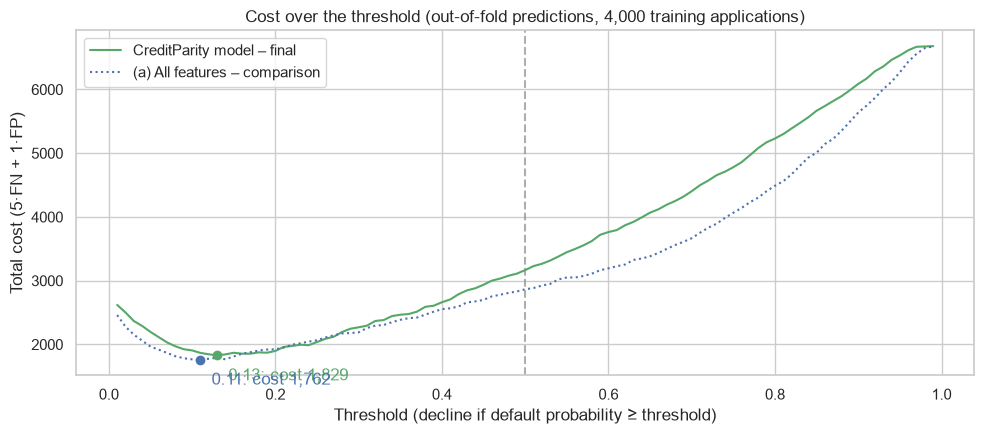

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, color, style in [(FINAL, "#55A868", "-"), (COMPARISON, "#4C72B0", ":")]:
    curve = cost_curves[name]
    ax.plot(curve["Threshold"], curve["Cost"], style, color=color, label=name)
    t = T_LOWER[name]
    c = curve.loc[curve["Threshold"] == t, "Cost"].iloc[0]
    ax.scatter([t], [c], color=color, zorder=5)
    ax.annotate(f"{t:.2f}: cost {c:,.0f}", (t, c), xytext=(8, -18), textcoords="offset points",
                color=color)
ax.axvline(0.5, ls="--", color="#8C8C8C", alpha=0.7)
ax.set_xlabel("Threshold (decline if default probability ≥ threshold)")
ax.set_ylabel("Total cost (5·FN + 1·FP)")
ax.set_title("Cost over the threshold (out-of-fold predictions, 4,000 training applications)")
ax.legend()
plt.tight_layout()
plt.show()

In [8]:
# Calibration of the CreditParity model by probability band
bands = pd.cut(p_oof[FINAL], [0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.6, 0.8, 1.0])
pd.DataFrame({"p": p_oof[FINAL], "y": y_oof}).groupby(bands, observed=True).agg(
    Applications=("y", "size"), Mean_predicted_PD=("p", "mean"),
    Observed_default_rate=("y", "mean")).round(3)

,Applications,Mean_predicted_PD,Observed_default_rate
"(0.0, 0.05]",504,0.027,0.012
"(0.05, 0.1]",458,0.073,0.061
"(0.1, 0.2]",644,0.146,0.165
"(0.2, 0.3]",541,0.248,0.281
"(0.3, 0.4]",423,0.349,0.322
"(0.4, 0.6]",645,0.492,0.451
"(0.6, 0.8]",470,0.698,0.687
"(0.8, 1.0]",315,0.881,0.933


**Result (a).** On the out-of-fold predictions, the cost-optimal threshold of the CreditParity model is **0.13**:

| Rule (out-of-fold, 4,000 applications) | Threshold | Cost | Recall | Precision | Approval rate |
|---|---|---|---|---|---|
| (a) Baseline: all features, threshold 0.5 | 0.50 | 2,865 | 0.616 | 0.733 | 71.9% |
| CreditParity model, default threshold | 0.50 | 3,166 | 0.571 | 0.717 | 73.4% |
| **CreditParity model, cost-optimal (CV) – final** | **0.13** | **1,829** | **0.954** | 0.456 | 30.0% |
| (a) Cost-optimal (CV) – comparison | 0.11 | 1,762 | 0.952 | 0.469 | 32.2% |

- **The cost-based threshold is the main lever.** For the CreditParity model, moving from 0.5 to 0.13 cuts the cost from 3,166 to 1,829 (−42%) and raises recall from 57% to 95%. Compared with the baseline (all features, 0.5), the cost is 36% lower.
- **The price of fairness.** At their cost-optimal thresholds, the CreditParity model costs 1,829 and the comparison model (a) 1,762, i.e. 4% more on the training data.
- **A flat optimum.** All thresholds from 0.12 to 0.17 are within 2% of the minimum cost. The per-fold optimum ranges from 0.13 to 0.20, so the exact value of 0.13 matters little for cost but should be monitored.
- **Calibration.** The CreditParity model is reasonably well calibrated (e.g. predicted 25%, observed 28% in the 0.2–0.3 band; predicted 15%, observed 17% in the 0.1–0.2 band), close to the theoretical threshold of 1/6 ≈ 0.17.

### b) The three-zone policy

The cost-optimal threshold decides *whether* an application is approved. The three zones decide *who* makes the decision and *how* it is communicated:

| Zone | Rule | What happens |
|---|---|---|
| 🟢 Green – auto-approve | PD < lower boundary | Approved automatically |
| 🟡 Yellow – manual review | lower ≤ PD < upper | A credit analyst decides, supported by a SHAP explanation. **This is the only manual workload.** |
| 🔴 Red – decline recommended | PD ≥ upper boundary | The system declines and gives the customer a SHAP-based explanation of the main reasons. The customer can request a human review. |

**Why three zones?**
- **Human oversight.** The EU AI Act classifies credit scoring as a high-risk AI system and requires effective human oversight. Uncertain cases are decided by a person.
- **GDPR Art. 22.** Applicants have the right not to be subject to a purely automated decision with significant effects, and the right to obtain human intervention and to contest the decision. Every red-zone decline comes with an explanation and the option to request a human review.
- **Analyst workload.** Clear cases are handled automatically, so analysts can focus on the uncertain ones.

**The boundaries.**
- **Lower boundary = cost-optimal threshold** from part (a). The zones do not change *which* applications are approved automatically, so the cost and recall from part (a) still apply. All cost figures refer to this single-threshold logic.
- **Upper boundary = precision rule.** An automatic decline should rarely hit a good customer. We choose the **lowest threshold at which at least 80% of the applications in the red zone are actual defaults** (precision ≥ 80%). A higher target means fewer wrongful automatic declines, but more cases for the analysts.

In [9]:
def upper_for_precision(p, y_true, lower, target):
    """Lowest threshold >= lower at which the red zone (p >= threshold) has precision >= target."""
    for t in THRESHOLDS[THRESHOLDS >= lower]:
        red = p >= t
        if red.any() and y_true[red].mean() >= target:
            return float(t)
    return 1.0

def zone_of(p, lower, upper):
    return np.where(p < lower, "Green", np.where(p >= upper, "Red", "Yellow"))

def zone_table(p, y_true, lower, upper):
    """Share of applications, defaults and good customers per zone."""
    zone = zone_of(p, lower, upper)
    rows = []
    for z in ["Green", "Yellow", "Red"]:
        m = zone == z
        defaults = int((m & (y_true == 1)).sum())
        rows.append({"Zone": z, "Applications": int(m.sum()), "Share": m.mean(),
                     "Defaults": defaults, "Good customers": int(m.sum()) - defaults,
                     "Default rate": defaults / max(m.sum(), 1),
                     "Share of all defaults": defaults / max((y_true == 1).sum(), 1)})
    table = pd.DataFrame(rows).set_index("Zone")
    table.loc["Total"] = [len(y_true), 1.0, int(y_true.sum()), int((y_true == 0).sum()),
                          y_true.mean(), 1.0]
    return table.astype({"Applications": int, "Defaults": int, "Good customers": int})

def policy_summary(p, y_true, lower, upper):
    """Key figures of a zone policy."""
    zone = zone_of(p, lower, upper)
    red = zone == "Red"
    single = single_threshold_metrics(p, y_true, lower)
    return {"Lower": lower, "Upper": upper,
            "Green": (zone == "Green").mean(), "Yellow (manual review)": (zone == "Yellow").mean(),
            "Red": red.mean(),
            "Red precision": y_true[red].mean() if red.any() else np.nan,
            "Good customers auto-declined (red)": int((red & (y_true == 0)).sum()),
            "Good customers declined (PD ≥ lower)": single["FP"],
            "Defaults auto-approved (green)": single["FN"],
            "Cost (single threshold)": single["Cost"]}

TARGETS = [0.75, 0.80, 0.85, 0.90]
T_UPPER = {name: upper_for_precision(p_oof[name], y_oof, T_LOWER[name], TARGET_PRECISION)
           for name in MODELS}
for name in MODELS:
    print(f"{name:30s} green < {T_LOWER[name]:.2f} ≤ yellow < {T_UPPER[name]:.2f} ≤ red")

print(f"\nCreditParity model, out-of-fold – zones {T_LOWER[FINAL]} / {T_UPPER[FINAL]}")
zone_table(p_oof[FINAL], y_oof, T_LOWER[FINAL], T_UPPER[FINAL]).round(3)

CreditParity model – final     green < 0.13 ≤ yellow < 0.62 ≤ red
(a) All features – comparison  green < 0.11 ≤ yellow < 0.58 ≤ red

CreditParity model, out-of-fold – zones 0.13 / 0.62


,Applications,Share,Defaults,Good customers,Default rate,Share of all defaults
Zone,,,,,,
Green,1201,0.300,61,1140,0.051,0.046
Yellow,2063,0.516,684,1379,0.332,0.512
Red,736,0.184,591,145,0.803,0.442
Total,4000,1.000,1336,2664,0.334,1.000


In [10]:
# Trade-off: target precision for automatic declines vs. manual review workload (out-of-fold)
def target_table(p_dict, y_true, uppers=None):
    rows = []
    for name in MODELS:
        for target in TARGETS:
            upper = (uppers[(name, target)] if uppers is not None
                     else upper_for_precision(p_dict[name], y_true, T_LOWER[name], target))
            rows.append({"Model": name, "Target precision": target,
                         **policy_summary(p_dict[name], y_true, T_LOWER[name], upper)})
    return pd.DataFrame(rows).set_index(["Model", "Target precision"])

targets_oof = target_table(p_oof, y_oof)
UPPERS_BY_TARGET = targets_oof["Upper"].to_dict()     # chosen on training data, reused on the test set
targets_oof[["Upper", "Green", "Yellow (manual review)", "Red", "Red precision",
             "Good customers auto-declined (red)"]].round(3)

Upper  Green  \
Model                         Target precision                 
CreditParity model – final    0.75               0.56  0.300   
                              0.80               0.62  0.300   
                              0.85               0.69  0.300   
                              0.90               0.75  0.300   
(a) All features – comparison 0.75               0.52  0.322   
                              0.80               0.58  0.322   
                              0.85               0.66  0.322   
                              0.90               0.73  0.322   

                                                Yellow (manual review)    Red  \
Model                         Target precision                                  
CreditParity model – final    0.75                               0.474  0.226   
                              0.80                               0.516  0.184   
                              0.85                               0.557  0.143   
                              0.90                               0.592  0.107   
(a) All features – comparison 0.75                               0.412  0.267   
                              0.80                               0.444  0.234   
                              0.85                               0.482  0.197   
                              0.90                               0.521  0.157   

                                                Red precision  \
Model                         Target precision                  
CreditParity model – final    0.75                      0.753   
                              0.80                      0.803   
                              0.85                      0.855   
                              0.90                      0.904   
(a) All features – comparison 0.75                      0.754   
                              0.80                      0.802   
                              0.85                      0.853   
                              0.90                      0.905   

                                                Good customers auto-declined (red)  
Model                         Target precision                                      
CreditParity model – final    0.75                                             223  
                              0.80                                             145  
                              0.85                                              83  
                              0.90                                              41  
(a) All features – comparison 0.75                                             263  
                              0.80                                             185  
                              0.85                                             116  
                              0.90                                              60

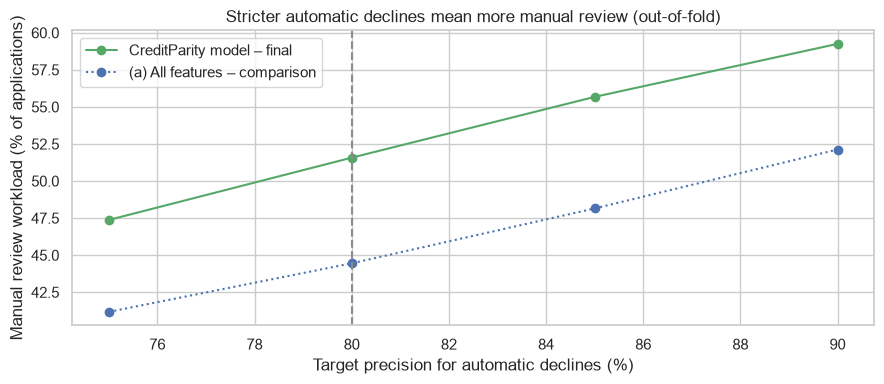

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
for name, color, style in [(FINAL, "#55A868", "-"), (COMPARISON, "#4C72B0", ":")]:
    d = targets_oof.loc[name]
    ax.plot(100 * d.index, 100 * d["Yellow (manual review)"], style, marker="o", color=color,
            label=name)
ax.axvline(100 * TARGET_PRECISION, ls="--", color="#8C8C8C")
ax.set_xlabel("Target precision for automatic declines (%)")
ax.set_ylabel("Manual review workload (% of applications)")
ax.set_title("Stricter automatic declines mean more manual review (out-of-fold)")
ax.legend()
plt.tight_layout()
plt.show()

In [12]:
# Stability of the boundaries of the CreditParity model across folds
fold_rows = []
for k in range(5):
    m = fold_id == k
    lo = cost_optimal_threshold(p_oof[FINAL][m], y_oof[m])
    up = upper_for_precision(p_oof[FINAL][m], y_oof[m], lo, TARGET_PRECISION)
    zone = zone_of(p_oof[FINAL][m], lo, up)
    fold_rows.append({"Fold": k + 1, "Lower": lo, "Upper": up,
                      "Manual review": round((zone == "Yellow").mean(), 3)})
pd.DataFrame(fold_rows).set_index("Fold").T

Fold,1,2,3,4,5
Lower,0.130,0.130,0.130,0.190,0.200
Upper,0.610,0.610,0.620,0.640,0.620
Manual review,0.498,0.532,0.518,0.438,0.405


**Result (b).** With the precision rule (≥ 80%), the boundaries of the CreditParity model are **0.13 and 0.62**:

| Zone (out-of-fold, CreditParity model) | Share | Defaults | Good customers | Default rate |
|---|---|---|---|---|
| 🟢 Green – auto-approve (PD < 0.13) | 30.0% | 61 | 1,140 | 5.1% |
| 🟡 Yellow – manual review (0.13 – 0.62) | 51.6% | 684 | 1,379 | 33.2% |
| 🔴 Red – decline recommended (PD ≥ 0.62) | 18.4% | 591 | 145 | 80.3% |

- **Automatic declines are reliable.** 80% of the applications in the red zone are actual defaults; 145 good customers are declined automatically (model (a) with the same rule: 185).
- **The price is a large manual workload.** The CreditParity model separates defaults and good customers less sharply than model (a), so the uncertain middle is wide: **52% of applications go to an analyst** (model (a): 44%).
- **Trade-off with the target precision** (out-of-fold, CreditParity model):

| Target precision | Upper boundary | Manual review | Red zone | Good customers auto-declined |
|---|---|---|---|---|
| 75% | 0.56 | 47.4% | 22.6% | 223 |
| **80%** | **0.62** | **51.6%** | **18.4%** | **145** |
| 85% | 0.69 | 55.7% | 14.3% | 83 |
| 90% | 0.75 | 59.2% | 10.7% | 41 |

  A lower target reduces the workload, but increases the wrongful automatic declines by about half (145 → 223 at 75%).
- **Stability.** Across the five folds, the upper boundary ranges from 0.61 to 0.64; the manual review share varies more (40.5% to 53.2%) because the lower boundary varies (0.13 to 0.20).

### c) Final evaluation on the test set

Now – and only now – we use the test set. Both models are trained on all 4,000 training applications and the thresholds chosen above are applied **without any change** to the 1,000 test applications.

In [13]:
y_test_arr = y_test.to_numpy()
p_test = {name: fit_model(X_train, y_train, spec).predict_proba(X_test)[:, 1]
          for name, spec in MODELS.items()}

rows = [("(a) Default threshold 0.5 – baseline", COMPARISON, 0.5),
        ("CreditParity model, default threshold 0.5", FINAL, 0.5),
        ("CreditParity model, cost-optimal – final", FINAL, T_LOWER[FINAL]),
        ("(a) Cost-optimal – comparison", COMPARISON, T_LOWER[COMPARISON])]
test_single = pd.DataFrame([{"Rule": r, **single_threshold_metrics(p_test[m], y_test_arr, t)}
                            for r, m, t in rows]).set_index("Rule")
display(test_single.round(3))

for r, m, t in rows:
    tn, fp, fn, tp = confusion_matrix(y_test_arr, (p_test[m] >= t).astype(int)).ravel()
    print(f"{r:40s} TP {tp}, TN {tn}, FP {fp}, FN {fn}")

,Threshold,Cost,Cost per 100 applications,Recall,Precision,Approval rate,FN,FP
Rule,,,,,,,,
(a) Default threshold 0.5 – baseline,0.50,700,70.0,0.626,0.736,0.716,125,75
"CreditParity model, default threshold 0.5",0.50,785,78.5,0.575,0.719,0.733,142,75
"CreditParity model, cost-optimal – final",0.13,436,43.6,0.964,0.461,0.302,12,376
(a) Cost-optimal – comparison,0.11,409,40.9,0.958,0.486,0.341,14,339


(a) Default threshold 0.5 – baseline     TP 209, TN 591, FP 75, FN 125
CreditParity model, default threshold 0.5 TP 192, TN 591, FP 75, FN 142
CreditParity model, cost-optimal – final TP 322, TN 290, FP 376, FN 12
(a) Cost-optimal – comparison            TP 320, TN 327, FP 339, FN 14


In [14]:
# Zone policy on the test set (target precision 80%)
test_policy = pd.DataFrame({name: policy_summary(p_test[name], y_test_arr, T_LOWER[name], T_UPPER[name])
                            for name in MODELS})
display(test_policy.round(3))

print(f"CreditParity model, test set – zones {T_LOWER[FINAL]} / {T_UPPER[FINAL]}")
test_zones = zone_table(p_test[FINAL], y_test_arr, T_LOWER[FINAL], T_UPPER[FINAL])
test_zones.round(3)

,CreditParity model – final,(a) All features – comparison
Lower,0.130,0.110
Upper,0.620,0.580
Green,0.302,0.341
Yellow (manual review),0.520,0.421
Red,0.178,0.238
Red precision,0.860,0.819
Good customers auto-declined (red),25.000,43.000
Good customers declined (PD ≥ lower),376.000,339.000
Defaults auto-approved (green),12.000,14.000
Cost (single threshold),436.000,409.000


CreditParity model, test set – zones 0.13 / 0.62


,Applications,Share,Defaults,Good customers,Default rate,Share of all defaults
Zone,,,,,,
Green,302,0.302,12,290,0.040,0.036
Yellow,520,0.520,169,351,0.325,0.506
Red,178,0.178,153,25,0.860,0.458
Total,1000,1.000,334,666,0.334,1.000


In [15]:
# Target precision table on the test set (boundaries chosen on the training data)
targets_test = target_table(p_test, y_test_arr, uppers=UPPERS_BY_TARGET)
targets_test[["Upper", "Green", "Yellow (manual review)", "Red", "Red precision",
              "Good customers auto-declined (red)"]].round(3)

Upper  Green  \
Model                         Target precision                 
CreditParity model – final    0.75               0.56  0.302   
                              0.80               0.62  0.302   
                              0.85               0.69  0.302   
                              0.90               0.75  0.302   
(a) All features – comparison 0.75               0.52  0.341   
                              0.80               0.58  0.341   
                              0.85               0.66  0.341   
                              0.90               0.73  0.341   

                                                Yellow (manual review)    Red  \
Model                         Target precision                                  
CreditParity model – final    0.75                               0.480  0.218   
                              0.80                               0.520  0.178   
                              0.85                               0.558  0.140   
                              0.90                               0.594  0.104   
(a) All features – comparison 0.75                               0.391  0.268   
                              0.80                               0.421  0.238   
                              0.85                               0.461  0.198   
                              0.90                               0.504  0.155   

                                                Red precision  \
Model                         Target precision                  
CreditParity model – final    0.75                      0.794   
                              0.80                      0.860   
                              0.85                      0.893   
                              0.90                      0.885   
(a) All features – comparison 0.75                      0.757   
                              0.80                      0.819   
                              0.85                      0.859   
                              0.90                      0.910   

                                                Good customers auto-declined (red)  
Model                         Target precision                                      
CreditParity model – final    0.75                                              45  
                              0.80                                              25  
                              0.85                                              15  
                              0.90                                              12  
(a) All features – comparison 0.75                                              65  
                              0.80                                              43  
                              0.85                                              28  
                              0.90                                              14

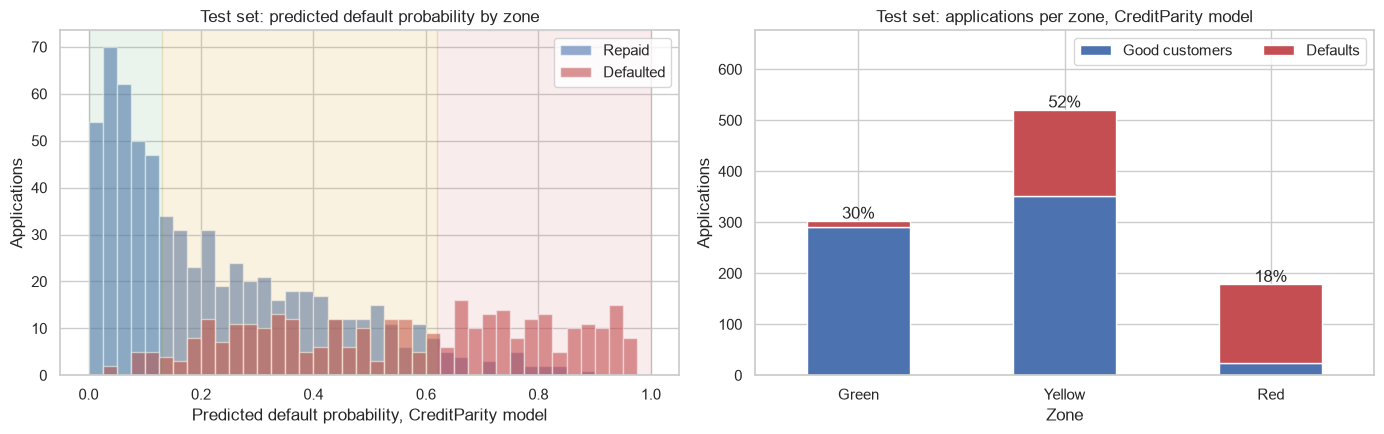

In [16]:
lo, up = T_LOWER[FINAL], T_UPPER[FINAL]
p, yt = p_test[FINAL], y_test_arr
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Left: distribution of default probabilities with the zone boundaries
bins = np.linspace(0, 1, 41)
axes[0].hist(p[yt == 0], bins=bins, alpha=0.6, label="Repaid", color="#4C72B0")
axes[0].hist(p[yt == 1], bins=bins, alpha=0.6, label="Defaulted", color="#C44E52")
axes[0].axvspan(0, lo, color=ZONE_COLORS["Green"], alpha=0.12)
axes[0].axvspan(lo, up, color=ZONE_COLORS["Yellow"], alpha=0.15)
axes[0].axvspan(up, 1, color=ZONE_COLORS["Red"], alpha=0.10)
axes[0].set_xlabel("Predicted default probability, CreditParity model")
axes[0].set_ylabel("Applications")
axes[0].set_title("Test set: predicted default probability by zone")
axes[0].legend()

# Right: composition of each zone
comp = test_zones.loc[["Green", "Yellow", "Red"], ["Good customers", "Defaults"]]
comp.plot.bar(stacked=True, color=["#4C72B0", "#C44E52"], ax=axes[1], rot=0)
axes[1].set_ylim(0, comp.sum(axis=1).max() * 1.3)
axes[1].legend(loc="upper right", ncol=2)
for i, z in enumerate(comp.index):
    axes[1].text(i, comp.loc[z].sum() + 5, f"{test_zones.loc[z, 'Share']:.0%}", ha="center")
axes[1].set_title("Test set: applications per zone, CreditParity model")
axes[1].set_ylabel("Applications")
plt.tight_layout()
plt.show()

**Result (c) – final evaluation on the test set (1,000 applications).**

**Headline: the cost-based threshold with the CreditParity model.**

| Rule (test set) | Cost | Recall | Precision | TP | FN | FP | TN |
|---|---|---|---|---|---|---|---|
| (a) Baseline: all features, threshold 0.5 | 700 | 0.626 | 0.736 | 209 | 125 | 75 | 591 |
| **CreditParity model, cost-optimal threshold 0.13** | **436 (−38%)** | **0.964** | 0.461 | 322 | 12 | 376 | 290 |
| (a) All features, cost-optimal 0.11 – comparison | 409 (−42%) | 0.958 | 0.486 | 320 | 14 | 339 | 327 |

With the CreditParity model, the cost of wrong decisions is **38% lower than with a standard model at the default threshold of 0.5** (436 vs. 700), and recall rises from 0.63 to 0.96. The model does not use gender or foreign worker status, and the age gap for creditworthy applicants drops from 0.81 to 0.59 (test set; Step 6). It remains an explainable logistic regression.

**Zones on the test set.**

| | CreditParity model – final | Model (a) – comparison |
|---|---|---|
| Boundaries | 0.13 / 0.62 | 0.11 / 0.58 |
| 🟢 Auto-approve | 30.2% | 34.1% |
| 🟡 Manual review | 52.0% | 42.1% |
| 🔴 Decline recommended | 17.8% | 23.8% |
| Red-zone precision | 86.0% | 81.9% |
| Good customers declined automatically (red) | 25 | 43 |
| Good customers with PD ≥ lower boundary (yellow + red) | 376 | 339 |
| Defaults auto-approved (green) | 12 | 14 |
| Cost (single-threshold logic) | 436 | 409 |

| Target precision (test set, CreditParity model) | Upper boundary | Manual review | Red zone | Red precision | Good customers auto-declined |
|---|---|---|---|---|---|
| 75% | 0.56 | 48.0% | 21.8% | 79.4% | 45 |
| **80%** | **0.62** | **52.0%** | **17.8%** | **86.0%** | **25** |
| 85% | 0.69 | 55.8% | 14.0% | 89.3% | 15 |
| 90% | 0.75 | 59.4% | 10.4% | 88.5% | 12 |

On the test set, the red-zone precision meets the 75%, 80% and 85% targets; at 90% it falls slightly short (88.5%), because the red zone is small. The test cost per 100 applications (43.6) is close to the out-of-fold value (45.7).

**The price of fairness.** Compared with model (a), the CreditParity model:
- costs **7% more** (436 vs. 409 on the test set), but its cost of wrong decisions is still **38% lower** than with the default threshold of 0.5 (700);
- sends more applications to manual review (**52% vs. 42%**);
- has a larger gender gap among good customers (0.21 vs. 0.11 on the test set), which works against men (Step 6).

In return:
- **automatic declines of creditworthy applicants aged 51+ fall by more than half**: 16 of 83 on the training data, compared with 41 of 83 with model (a) and 40 of 83 with a model without age correction (Step 6); on the test set 4 of 21 vs. 8 of 21 with model (a);
- the age gap for creditworthy applicants (EOD) falls from 0.81 to 0.59 (test set);
- fewer good customers are declined automatically (25 vs. 43) and fewer defaults are approved automatically (12 vs. 14);
- the model treats men and women with the same features identically, because gender is not an input.

**Decision for CreditParity.** The CreditParity model with the cost-optimal threshold **0.13** as the green/yellow boundary and **0.62** (target precision 80%) as the yellow/red boundary. Model (a) is kept as the comparison model.

**Limitations.**
- The 80% precision target for automatic declines is a business assumption. Before deployment it should be validated with the bank's risk and compliance teams. In operation, the thresholds should be monitored regularly and adjusted to the available analyst capacity: a higher target reduces wrongful automatic declines but increases the manual review workload.
- About 52% of applications go to manual review. The bank can adjust the precision target to balance analyst workload against wrongful automatic declines; thresholds should be monitored and adjusted to the available analyst capacity.
- The 5:1 cost ratio is an assumption. A different ratio leads to a different lower boundary; the cost curve is flat between 0.12 and 0.17.
- The cost figures assume that every application with PD ≥ 0.13 is declined. Analyst decisions in the yellow zone and human reviews requested in the red zone may change some of these decisions; the dataset cannot show how this affects cost.
- The model does not use gender or foreign worker status as inputs. The remaining gender gap among good customers (0.21 on the test set, 0.25 out-of-fold) works against men and results from differences in other features. It should be reviewed legally (direct vs. indirect discrimination) and monitored in operation.
- Age is used directly as a partial correction for its proxies. This also needs legal review.
- Unlike typical lending data, older applicants in this dataset default far more often than younger ones (76% vs. 5% on the test set).
- The dataset is synthetic. The separation between defaults and good customers may differ in real loan data.